# Schwarzchild orbit-superposition modelling

My personal notes following the Agama example. 

In [1]:
import agama, numpy, matplotlib, matplotlib.pyplot as plt
%matplotlib inline
plt.rc('figure', dpi=100)
plt.rc('font', size=10)
plt.rc('axes', linewidth=0.5)
plt.rc('mathtext', fontset='stix')

In [2]:
q = 0.6
total_mass = 1.0 
bh_mass = 0.1 
pot_stars = agama.Potential(type="spheroid", gamma=1, beta=5, mass=total_mass, scaleRadius=1,axisRatioZ=q)
dens_stars = pot_stars # reassignment? why? 
pot_bh = agama.Potential(type="Plummer",mass=bh_mass,scaleRadius=0) # interesting!, zero?
pot_total = pot_stars + pot_bh # pot_total = agama.Potential(pot_stars, pot_bh). cool how he changed the internal functions!

### Creating orbital initial conditions 

The default method for sampling takes positions from the density profile and gives velocities through performing the eddington inversion with poisson's equation. It uses the spericalized density and potential pair. Not sure on the details. But, the important part is that this properly samples all types of orbits that are available. Uniformly sampling the density profile is a good way to do this but certainly isn't the best. There's a work by Neureiter et al. 2021 who studied this further to come up with a more optimal sampling. Or, they did a bigger project and good sampling is part of it. 

In [3]:
num_orbits = int(1e5)
ic, mass = dens_stars.sample(num_orbits,potential = pot_total)

### Detour. 

Why not see what these orbits give? do they reproduce the density profile as a function of time? Why go through Schwartzchild modeling if I can already get a set of initial conditions?


_NOTE_

Eugene doesn't like the name target... I like it! I actually think it's quite clear. this is the `target` as in what we want the model to reproduce. It's the goal of the schwartzchild modeling. We want to reproduce a given density profile or kinematic shell... right? 

So. I wanted to do this by hand, but it's a pain and Agama already does that. We want to get the "mass" in each cell. So, we have to descritize the meridonal plane, and then compute how much time a single orbit spends within that cell. Very nice! 


But, I'm a little confused on the set up. 

```python
gridR = agama.nonuniformGrid(9, 0.1, 10)
gridz = agama.nonuniformGrid(8, 0.1, 5)
target_density = agama.Target(type='DensityCylindricalTopHat', gridR=gridR, gridz=gridz)
```
This piece of the code is fine. We're creating the edges of the cells. So, when we evaluate the target... **D**, it will be in a $(9-1)\times(8-1)$ grid. Because, we'll evaluate *something* within each cell. 

I'm a but confused on this set up: 
```python
pot_stars = agama.Potential(type='Spheroid', gamma=1, 
                            beta=5, mass=total_mass, 
                            scaleRadius=1, axisRatioZ=q)
dens_stars = pot_stars
constraints_density = target_density(dens_stars)
```

this `constraints_density` returns the mass in each cell. So, it must be internal to Agama that when you pass the potential of an object to a `Agama.Target.DensityCylindricalTopHat` it knows to return the mass within each grid cell... 

Also, a target has no methods, but, it's type is 
```python
print(type(target))
```
`agama.Target`. However, it appears "list-like" because it can be indexed. 
```python
print(taget[0])
```
returns 
`R=0.05, z=0.05, m=0,`
which is a string. Weird. Also, it appears that "m" is referring to "mass", but, perhaps if we do a kinematic target, it would still print "m"? 

In [4]:
integration_time = 1e2*pot_total.Tcirc(ic)
gridR           =   agama.nonuniformGrid(20, 0.05, 10)
gridz           =   agama.nonuniformGrid(20, 0.01, 10)
target          =   agama.Target(type='DensityCylindricalTopHat', gridR=gridR, gridz=gridz)
D, orbits       =   agama.orbit(potential=pot_total, ic=ic, time=integration_time, dtype=object, targets=target)
w               =   numpy.ones(len(ic)) * total_mass / len(ic)      # equal weights from sampling
mass_discrete   =   D.T.dot(w)                                      # mass per cell
mass_true       =   target(dens_stars)        

shape = (len(gridz)-1, len(gridR)-1)
mass_d = mass_discrete.reshape(shape)
mass_t = mass_true.reshape(shape)
resid = (mass_d - mass_t) / mass_t
                      # analytic mass per cell (same cells)

100000 orbits complete (684.9 orbits/s)


[Text(0.5, 0, 'x'), Text(0, 0.5, 'z'), None]

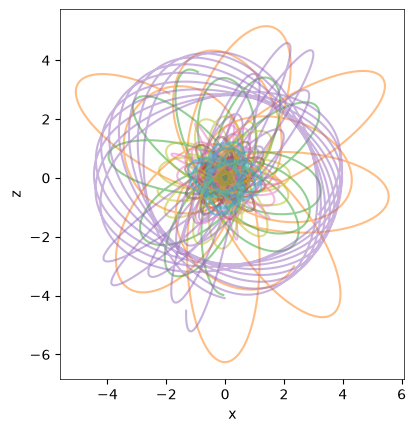

In [5]:
fig,axis=plt.subplots(1,1)
nsteps = int(1e4)
index_orbit = 15
for index_orbit in range(20):
    tsteps = numpy.linspace(0,integration_time[index_orbit]/10,nsteps)
    axis.plot(orbits[index_orbit].x(tsteps),orbits[index_orbit].y(tsteps),alpha=.50)
axis.set(xlabel="x", ylabel="z",aspect="equal")

Visualize the density. Lets look at the theoretical curve. The discritized theoretical version, the binned orbits, and then the residual between the two 

In [6]:
RR,ZZ = numpy.meshgrid(gridR,gridz)
xyz = numpy.column_stack((RR.ravel(),numpy.zeros_like(RR.ravel()),ZZ.ravel()))
rho_true = dens_stars.density(xyz).reshape(RR.shape)

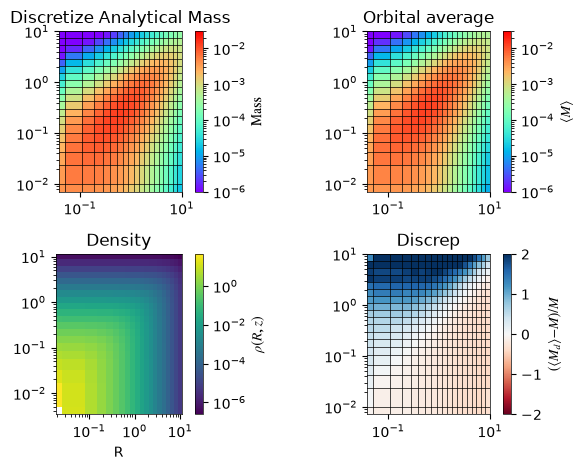

In [7]:
fig,axis=plt.subplots(2,2)

m = axis[1][0].pcolormesh(gridR,gridz,rho_true,norm=matplotlib.colors.LogNorm(),shading="auto")
fig.colorbar(m,label=r"$\rho (R,z)$")
axis[1][0].set(xscale="log",yscale="log",xlabel="R",aspect="equal",title="Density",)

# now do the discretized true version 
m=axis[0][0].pcolormesh(gridR,gridz,mass_t,cmap="rainbow",norm=matplotlib.colors.LogNorm(vmin=1e-6, vmax=3e-2),)
axis[0][0].vlines(gridR,ymin=gridz.min(),ymax=gridz.max(),color="k",linewidth=0.5)
axis[0][0].hlines(gridz,xmin=gridR.min(),xmax=gridR.max(),color="k",linewidth=0.5)
axis[0][0].set(xscale="log",yscale="log",title="Discretize Analytical Mass",aspect="equal")
fig.colorbar(m,label=r"$\rm{Mass}$",)

# now do the discretized the orbit average 
m=axis[0][1].pcolormesh(gridR,gridz,mass_d,cmap="rainbow",norm=matplotlib.colors.LogNorm(vmin=1e-6, vmax=3e-2),)
axis[0][1].vlines(gridR,ymin=gridz.min(),ymax=gridz.max(),color="k",linewidth=0.5)
axis[0][1].hlines(gridz,xmin=gridR.min(),xmax=gridR.max(),color="k",linewidth=0.5)
axis[0][1].set(xscale="log",yscale="log",title="Orbital average",aspect="equal")
fig.colorbar(m,label=r"$\left<M\right>$",)


# now do the discretized the orbit average 
m=axis[1][1].pcolormesh(gridR,gridz,(mass_d-mass_t)/mass_t,cmap="RdBu",vmin=-2,vmax=2); 
axis[1][1].vlines(gridR,ymin=gridz.min(),ymax=gridz.max(),color="k",linewidth=0.5)
axis[1][1].hlines(gridz,xmin=gridR.min(),xmax=gridR.max(),color="k",linewidth=0.5)
axis[1][1].set(xscale="log",yscale="log",title="Discrep",aspect="equal")
fig.colorbar(m,label=r"$\left(\left< M_{d} \right> - M\right)/M$")
fig.tight_layout()

Note. Agama also pointed out that, it's problematic that the amount of mass per bin varys so much. So, you'd want to pick a binning to try and modify the volume so that we have as close to equal mass as possible per bin. okay! We are off by a few orders of magnitude.! 


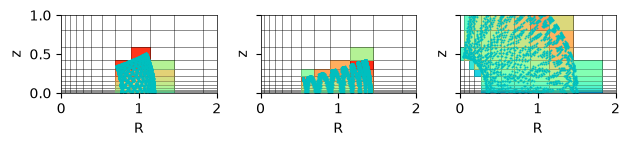

In [8]:
def show_orbit(index, ax):
    orbit = orbits[index]
    t = numpy.linspace(orbit[0], orbit[-1], 2500)  # show the orbit at equally spaced moments in time
    xv = orbit(t)
    orbit_R = (xv[:,0]**2 + xv[:,1]**2)**0.5
    orbit_z = numpy.abs(xv[:,2])
    ax.pcolormesh(gridR, gridz, D[index].reshape(len(gridz)-1, len(gridR)-1),
        edgecolor=(0,0,0,0.25), lw=0.5, norm=matplotlib.colors.LogNorm(vmin=1e-4, vmax=3e-1), cmap='rainbow')
    ax.scatter(orbit_R, orbit_z, color='c', marker='o', lw=0, s=2)

# pick up a few orbits with mean radii around unity, but different inclinations
orbit_radius = numpy.mean(pot_total.Rperiapo(ic), axis=1)
num_show = 3
select = numpy.argsort(abs(orbit_radius - 1.0))[[0,2,10]]
ax = plt.subplots(1, num_show, figsize=(6.4, 3), sharex=True, sharey=True)[1]
for i in range(num_show):
    show_orbit(select[i], ax[i])
    ax[i].set(xlim=[0,2],ylim=[0,1],xlabel="R",ylabel="z",aspect="equal")
plt.tight_layout()

this makes sense. we have z=symmetry when we do this. So, I did teh absolute value in |z|. And, the more time an orbit spends in a place, the more mass that cell gets.

### Determining the orbit weights

- $D$ = the `D` from the orbit output. This data was tracked during the orbits. 
- $r$ = the mass in each cell from the analytical model 
$$ \bf{D} \vec{w} = \vec{r} $$

It's so wild! Agama uses `CVXOPT`, which is an external code!! Here is it's documentation: 

https://cvxopt.org/userguide/intro.html

Or, at least this is a python adaptation. I believe that Agama is linking against the *C* code. So, it might not be the same as this python adaptation. Or, perhaps this python package is a wrapper to the faster C code. Not sure. totally fine. The documentation is interesting. It pulls from a textbook that solves regression problems and presents their methods. 

In [9]:
weights = agama.solveOpt(matrix=D.T, rhs = mass_true)
print('Orbit weights: %s, total mass: %g' % (weights, sum(weights)))

Using a custom optimized KKT solver
numVariables=100000, numConstraints=361, numConsIneq=100000
Benchmarking BLAS backends for matrix size=(361,100000): cvxopt=0.06 s, numpy=0.076 s, scipy=0.073 s => choosing cvxopt
     pcost       dcost       gap    pres   dres   k/t
 0:  0.0000e+00 -0.0000e+00  1e+05  3e+02  3e+02  1e+00
 1:  0.0000e+00 -1.8908e-01  7e+03  6e+01  6e+01  4e-03
 2:  0.0000e+00 -8.1980e-05  2e-03  3e-02  3e-02  3e-05
 3:  0.0000e+00 -2.1275e-05  3e-04  1e-02  1e-02  2e-05
 4:  0.0000e+00 -3.5423e-06  6e-05  6e-03  6e-03  1e-05
 5:  0.0000e+00 -1.2383e-06  9e-06  2e-03  2e-03  4e-06
 6:  0.0000e+00 -5.6313e-07  2e-06  3e-04  3e-04  3e-07
 7:  0.0000e+00 -1.8524e-08  5e-08  9e-06  9e-06  1e-08
 8:  0.0000e+00 -1.8558e-10  5e-10  9e-08  9e-08  1e-10
Optimal solution found.
Orbit weights: [7.08399569e-06 5.81046428e-06 1.00359361e-05 ... 8.62948864e-06
 7.62497670e-06 7.47488569e-06], total mass: 1.00248


This is a regularization science. Here, we can impart another constrain that there's the total mass is conserved. Kinda crazy how it's done. So, I don't know the mathematics that well behind it, but, it's a lienar system subject to constraints. The constrain is that the sum of the weights is equal to one. So, that makes it a linear program and not a quadratic problem yet. **What does OPT stand for?** optimal?

In [15]:
weights = agama.solveOpt(
    matrix  = [D.T, numpy.ones((1,num_orbits))],
    rhs     = [mass_true, [total_mass]]
)
print('Orbit weights: %s, total mass: %g' % (weights, sum(weights)))

Using a custom optimized KKT solver
numVariables=100000, numConstraints=362, numConsIneq=100000
     pcost       dcost       gap    pres   dres   k/t
 0:  0.0000e+00 -0.0000e+00  1e+05  3e+02  3e+02  1e+00
 1:  0.0000e+00 -1.8846e-01  7e+03  6e+01  6e+01  4e-03
 2:  0.0000e+00 -8.8810e-05  3e-03  4e-02  4e-02  3e-05
 3:  0.0000e+00 -2.0913e-05  3e-04  1e-02  1e-02  2e-05
 4:  0.0000e+00 -4.1833e-06  7e-05  6e-03  6e-03  1e-05
 5:  0.0000e+00 -1.3699e-06  1e-05  2e-03  2e-03  4e-06
 6:  0.0000e+00 -6.7073e-07  2e-06  3e-04  3e-04  4e-07
 7:  0.0000e+00 -2.2237e-08  6e-08  1e-05  1e-05  1e-08
 8:  0.0000e+00 -2.2315e-10  6e-10  1e-07  1e-07  1e-10
 9:  0.0000e+00 -2.2314e-12  6e-12  1e-09  1e-09  1e-12
Optimal solution found.
Orbit weights: [7.08349315e-06 5.81445667e-06 1.00404168e-05 ... 8.62801601e-06
 7.63145557e-06 7.47303774e-06], total mass: 1


KKT solver? why are there 9 steps? it must be an iterative solver. The pcost must come from the quadratic solving term. Not sure what D cost is... nor the gap... But, it drops. What is pres? p-residual? d-residual? k? t? k/t? they decrease reach time. I do see that the total mass is now conserved, which is better. 

If we undersample the orbital space, we can no longer find the weights that proper reproduce the density constrain and the total mass constrain. 

In [35]:
num_orbits2 = num_orbits//8
try:
    weights2 = agama.solveOpt(
        matrix=[D[:num_orbits2].T, numpy.ones((1, num_orbits2))],
        rhs=[mass_true, [total_mass]])
except Exception as e:
    print(e)

Using a custom optimized KKT solver
numVariables=12500, numConstraints=362, numConsIneq=12500
     pcost       dcost       gap    pres   dres   k/t
 0:  0.0000e+00 -0.0000e+00  1e+04  1e+02  1e+02  1e+00
 1:  0.0000e+00 -1.8841e-01  9e+02  2e+01  2e+01  4e-03
 2:  0.0000e+00 -6.6380e-04  2e-02  1e-01  1e-01  2e-04
 3:  0.0000e+00 -1.1731e-04  2e-03  3e-02  3e-02  2e-04
 4:  0.0000e+00 -5.2995e-05  8e-04  2e-02  2e-02  1e-04
 5:  0.0000e+00 -1.4172e-05  1e-04  6e-03  6e-03  4e-05
 6:  0.0000e+00 -8.4267e-06  3e-05  2e-03  2e-03  6e-06
 7:  0.0000e+00 -5.4924e-07  2e-06  1e-04  1e-04  4e-07
 8:  0.0000e+00 -5.7342e-09  2e-08  1e-06  1e-06  5e-09
 9:  0.0000e+00 -5.7335e-11  2e-10  1e-08  1e-08  5e-11
Optimal solution found.


Now, I can add the qudratic term, to get us a more optimal solution. Here, we will let the solution tend towards one where we have a relative error in each cell of 1 percent. 

- **rpenq**: **r** - constrain vector (RHS). **PEN** = penality. **q** = quadratic. 

In our case, the quadratic form $\mathcal{Q}$ is diagonal. the elements are the inverses of the uncertainties. 

- does diagonal mean that we don't have mixed constraints or correlations? i.e., the density in one cell isn't correlated with the density in another, right? 

$$\mathcal{Q} = \frac{1}{2} \vec{w}^{T}\mathsf{Q} \vec{w} $$

I'm realy not sure why we have repeated use of Q... Fancy $\mathcal{Q}$ with regular $\mathsf{Q}$

NOTE

- an infinite penalty means to the coresponding constraint has to be satisfied exactly. 
```python 
rpenq=[2*constraints_density_uncertainty**-2, [numpy.inf]]
```
- Okay. I get it. `constraints_density_uncertainty` corresponds to the RHS of `mass_true`. Whilte `numpy.inf` corresponds to `[total_mass]`. 


1.0

In [74]:
factor = 10
constraints_density_uncertainty = 0.01 * mass_true
weights2 = agama.solveOpt(
    matrix=[D[:num_orbits//factor].T, numpy.ones((1, num_orbits//factor))],
    rhs=[mass_true, [total_mass]],
    rpenq=[2*constraints_density_uncertainty**-2, [numpy.inf]])

def check_solution(factor=10):
    actual_density = D[:num_orbits//factor].T.dot(weights2)
    bad_cells = numpy.where(abs(actual_density - mass_true) > constraints_density_uncertainty)[0]
    for c in bad_cells:
        print('cell %s, required mass=%g, actual mass=%g, difference=%.3g%%' %
            (target[c], mass_true[c], actual_density[c],
             (actual_density[c]/mass_true[c]-1)*100))

check_solution(factor=factor)

Using a custom optimized KKT solver
numVariables=10361, numConstraints=362, numConsIneq=10000
     pcost       dcost       gap    pres   dres
 0:  6.3223e-13 -1.0007e+00  1e+04  1e+02  1e+02
 1:  5.6048e-12 -1.0004e+00  1e+02  1e+00  1e+00
 2:  1.7994e-08 -9.7643e-01  9e+00  8e-02  8e-02
 3:  1.6857e-06 -9.6015e-01  3e+00  2e-02  2e-02
 4:  4.4501e-06 -7.7718e-01  2e+00  8e-03  8e-03
 5:  4.3824e-06 -5.8149e-01  9e-01  4e-03  4e-03
 6:  4.3378e-06 -5.4103e-01  8e-01  4e-03  4e-03
 7:  4.4723e-06 -5.2454e-01  8e-01  3e-03  3e-03
 8:  6.4181e-06 -4.8551e-01  8e-01  3e-03  3e-03
 9:  7.5006e-05 -2.4056e-01  8e-01  3e-03  3e-03
10:  5.6858e-05 -2.8196e-01  8e-01  3e-03  3e-03
11:  1.1619e-03  6.5675e-01  8e-01  3e-03  3e-03
12:  3.7441e-02  6.2150e+00  1e+00  3e-03  3e-03
13:  5.0500e-01  2.3890e+01  2e+00  3e-03  3e-03
14:  2.2200e+01  1.4258e+02  3e+01  3e-03  3e-03
15:  2.4028e+01  1.4711e+02  4e+01  3e-03  3e-03
16:  2.6275e+02  3.0562e+02  9e+01  7e-04  7e-04
17:  3.0640e+02  3.0756e+

Now try the linear solver. It's a different type. **r**ight-hand-side, **pen**aliized, **l**inear, condtion. The doc says that this one will allow all the penality to be stored in a few points instead of trying to bend the solution to satisfy all points and speading the error out between all of them more uniformly. 

just seems like a different option. Not sure which one is better. 


In [75]:
weights2 = agama.solveOpt(
    matrix=[D[:num_orbits//factor].T, numpy.ones((1,num_orbits//factor))],
    rhs=[mass_true, [total_mass]],
    rpenl=[constraints_density_uncertainty**-1, [numpy.inf]]
)
check_solution(factor=factor)

Using a custom optimized KKT solver
numVariables=10722, numConstraints=362, numConsIneq=10722
     pcost       dcost       gap    pres   dres   k/t
 0:  0.0000e+00 -0.0000e+00  1e+10  1e+02  3e-08  1e+00
 1: -9.8968e-01 -9.8934e-01  1e+08  1e+00  3e-10  1e-02
 2: -9.3844e+01 -9.2846e+01  7e+07  7e-01  2e-10  1e+00
 3: -1.2352e+02 -1.2312e+02  1e+07  1e-01  4e-11  4e-01
 4: -3.9269e+02 -3.9194e+02  1e+07  1e-01  4e-11  8e-01
 5: -5.9985e+02 -5.9927e+02  4e+06  4e-02  1e-11  6e-01
 6: -2.0476e+03 -2.0464e+03  4e+06  4e-02  1e-11  1e+00
 7: -1.4447e+03 -1.4444e+03  5e+05  5e-03  1e-12  2e-01
 8: -3.8121e+03 -3.8115e+03  5e+05  5e-03  1e-12  6e-01
 9: -1.2344e+04 -1.2342e+04  5e+05  5e-03  1e-12  2e+00
10: -2.0083e+04 -2.0080e+04  3e+05  3e-03  9e-13  3e+00
11: -1.5140e+04 -1.5138e+04  3e+04  3e-04  8e-14  2e+00
12: -6.7280e+03 -6.7271e+03  1e+04  1e-04  3e-14  8e-01
13: -5.1912e+03 -5.1907e+03  7e+03  7e-05  2e-14  6e-01
14: -2.4699e+03 -2.4696e+03  3e+03  3e-05  1e-14  3e-01
15: -1.8227e

### Create N-body snapshots

the documentation does confirm that this returns particles on the same orbits, albeit it at different phases. They are exact, however. But, once an n-body code would run, the collisions would make that stop. 

In [76]:
Nbody= int(1e5)
snap_posvel, snap_mass = agama.sampleOrbitLibrary(Nbody, orbits, weights)

wow! that took a long time to sample. Three minutes? what did I do wrong? maybe it's because I have a large orbit library? who knows

### Examining the model 

It clicked! I see why there's a different variable for *den_stars*. It's because... it's because we're only sampling one component of the density distribution for the orbits. We're not giving density distribution of the black hole a corresponding stellar sampling.

- questions: what is "a"? axis-symmetric symmetry? in the documentation, it's clearly "Axisymmetric". Maybe "a" is just a shorthand alias... 
    - I tested it. It the leading character is "a", case-insensitive, then it will pick the axis-symmetric case. 

In [87]:
pot_stars_nbody = agama.Potential(type="multipole", particles=(snap_posvel, snap_mass),symmetry="adds")
E_kin = 0.5 * numpy.sum(snap_mass[:,None] * snap_posvel[:,3:6]**2)
E_pot = 0.5 * numpy.sum(snap_mass * pot_stars_nbody.potential(snap_posvel[:,0:3]))
print('Epot=%g, Ekin=%g, virial ratio=%g' % (E_pot, E_kin, -2*E_kin/E_pot))

# and yess, include the Black hole! 
E_pot += 0.5 * (numpy.sum(snap_mass * pot_bh.potential(snap_posvel[:,0:3])) +
    pot_bh.totalMass() * pot_stars_nbody.potential(0,0,0))
print('Epot=%g, Ekin=%g, virial ratio=%g' % (E_pot, E_kin, -2*E_kin/E_pot))

Epot=-0.463895, Ekin=0.348632, virial ratio=1.50307
Epot=-0.697206, Ekin=0.348632, virial ratio=1.00009


okay, the virial ratio is good, but that's one constrain. The kinetic and potential energy could still be incredibly incorrect. So, let's try them seeing if they are correct individually as well. 

There's the way to measure the potential energy, which is to integrate the density over the potential. Which is kinda crazy. We can evalutae this 3D integral numerically. Looks like $r,\theta$ aren't going to hack it, so we're changing variables: $(r,\theta) \rightarrow (\xi,\eta)$
$$
\begin{align}
\xi &= \tanh(r)\\
\eta &= \cos(\theta)\\
\end{align}
$$


I went line by line through the tutorials code below. It makes sense. There's the jacobian for the change of variables. And we integrate over this space. 

In [118]:
def compute_potential_energy(density,potential):
    def integrand(var):
        # unpack them 
        xi, costheta = var.T
        sintheta = (1-costheta**2)**0.5
        r = numpy.arctanh(xi)
        jac = 2*numpy.pi * r**2 / (1-xi**2)
        x = numpy.column_stack((r*sintheta,r*0,r*costheta))
        return numpy.nan_to_num(density.density(x)*potential.potential(x)*jac)
    with numpy.errstate(all="ignore"):
        return 0.5*agama.integrateNdim(integrand, lower=[0,-1], upper=[1,1])[0]

E_pot_true = (compute_potential_energy(dens_stars, pot_total) +
0.5 * pot_bh.totalMass() * pot_stars.potential(0,0,0))
print('True Epot=%g; fractional difference from Nbody: %.2g' % (E_pot_true, E_pot/E_pot_true-1))

True Epot=-0.695364; fractional difference from Nbody: 0.0026


So yes! we're in equalibrium. I want to look at what this looks like:

In [130]:
downselect=numpy.random.choice(numpy.arange(Nbody),size=(200),replace=False)

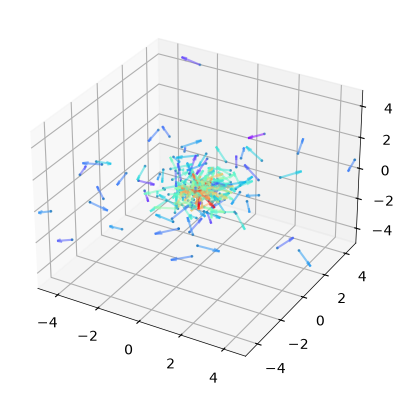

In [179]:
limits=5
speed = numpy.sum(snap_posvel[downselect,3:6]**2,axis=1)**(1/2)
colors=matplotlib.colormaps["rainbow"](matplotlib.colors.Normalize(vmin=speed.min(),vmax=speed.max()*(2/3))(speed))
fig=plt.figure()
axis=fig.add_subplot(111,projection="3d")
axis.scatter(snap_posvel[downselect,0],
             snap_posvel[downselect,1],
             snap_posvel[downselect,2],s=1)


axis.set(xlim=[-limits,limits],
         ylim=[-limits,limits],
         zlim=[-limits,limits])

colors[:,3] = 0.5
axis.quiver(snap_posvel[downselect,0],
            snap_posvel[downselect,1],
            snap_posvel[downselect,2],
            snap_posvel[downselect,3]/speed,
            snap_posvel[downselect,4]/speed,
            snap_posvel[downselect,5]/speed,color=colors)


In [178]:
colors=matplotlib.colormaps["rainbow"](matplotlib.colors.Normalize(vmin=0,vmax=2)(speed))

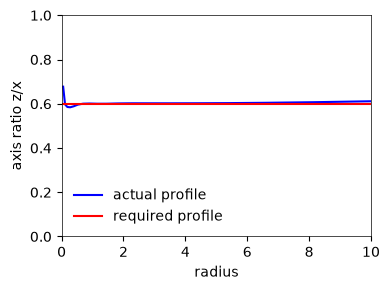

In [ ]:
axes = pot_stars_nbody.principalAxes(gridR)[0]
plt.figure(figsize=(4,3))
plt.plot(gridR, axes[:,2] / axes[:,0], c='b', label='actual profile')
plt.axhline(q, color='r', label='required profile')
plt.xlim(min(gridR), max(gridR))
plt.ylim(0, 1)
plt.xlabel('radius')
plt.ylabel('axis ratio z/x')
plt.legend(loc='lower left', frameon=False)
plt.tight_layout()

lets look at the distribution of the velocities! 

this are elegant ways of writing it down

In [182]:
snap_R = numpy.sum(snap_posvel[:,0:2]**2,axis=1)**0.5
snap_r = numpy.sum(snap_posvel[:,0:3]**2,axis=1)**0.5
snap_vr =numpy.sum(snap_posvel[:,0:3] * snap_posvel[:,3:6],axis=1) / snap_r
snap_vphi = (snap_posvel[:,0] * snap_posvel[:,4] - snap_posvel[:,1]*snap_posvel[:,3]) / snap_R
snap_vtheta = (numpy.sum(snap_posvel[:,0:2] * snap_posvel[:,3:5], axis=1) / snap_R * snap_posvel[:,2] - snap_R * snap_posvel[:,5]) / snap_r

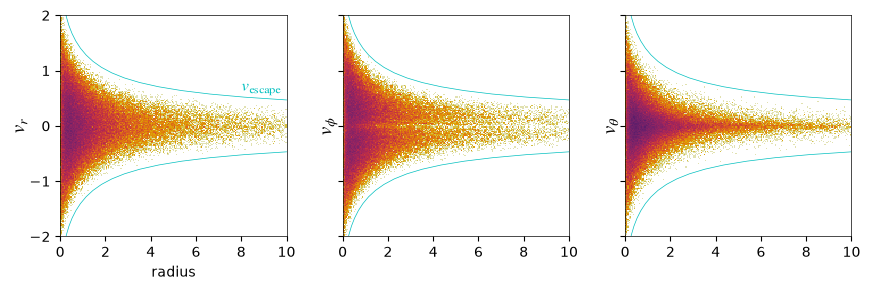

In [183]:
ax = plt.subplots(1, 3, figsize=(9, 3), sharex=True, sharey=True)[1]
bins_r = numpy.linspace(0, 10, 200)
bins_v = numpy.linspace(-2, 2, 200)
hist_params = dict(
    bins=(bins_r, bins_v),
    weights=snap_mass / (bins_r[1]-bins_r[0]) / (bins_v[1]-bins_v[0]),
    norm=matplotlib.colors.LogNorm(vmin=5e-3, vmax=5),
    cmap='hell_r')
ax[0].hist2d(snap_r, snap_vr, **hist_params)
ax[1].hist2d(snap_r, snap_vphi, **hist_params)
ax[2].hist2d(snap_r, snap_vtheta, **hist_params)
ax[0].set_xlabel('radius')
ax[0].set_ylabel(r'$v_r$', labelpad=0, fontsize=14)
ax[1].set_ylabel(r'$v_\phi$', labelpad=0, fontsize=14)
ax[2].set_ylabel(r'$v_\theta$', labelpad=0, fontsize=14)
ax[0].set_xlim(0, 10)
ax[0].set_ylim(-2, 2)
# overplot the escape velocity as a function of radius
v_esc = (-2 * pot_total.potential(numpy.column_stack((gridR, gridR*0, gridR*0))))**0.5
for a in ax:
    a.plot(gridR,  v_esc, color='c', lw=0.5)
    a.plot(gridR, -v_esc, color='c', lw=0.5)
ax[0].text(10, v_esc[-1]*1.1, r'$v_{\rm escape}$ ', ha='right', va='bottom', color='c', fontsize=12)
plt.tight_layout()


I used a way bigger library, so, this is why I don't have the clumps compared to the tutorial

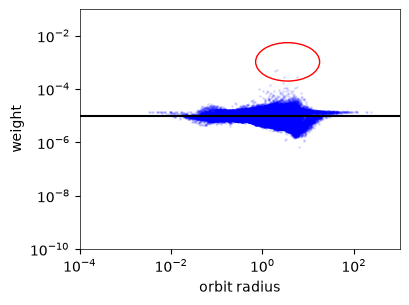

In [196]:
plt.figure(figsize=(4,3))
ax = plt.axes([0.18, 0.18, 0.8, 0.8])
ax.scatter(orbit_radius, weights, s=1, color='b', clip_on=False,alpha=0.1)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-4, 1e3)
ax.set_ylim(1e-10, 1e-1)
ax.set_xlabel('orbit radius')
ax.set_ylabel('weight')
ax.add_artist(matplotlib.patches.Ellipse((0.65, 0.78), 0.2, 0.16, fill=False, color='r', transform=ax.transAxes))
ax.hlines(1/num_orbits,xmin=1e-4,xmax=1e3,color="k")
None

the velocity anisotropy ! 

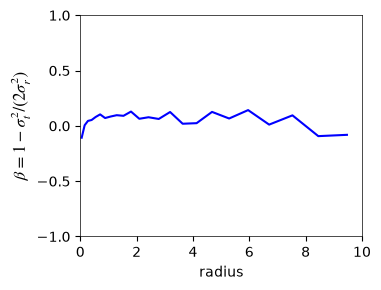

In [197]:
def plot_beta_profile(snap_posvel, snap_mass):
    snap_r   =  numpy.sum(snap_posvel[:,0:3]**2, axis=1)**0.5
    snap_vr2 = (numpy.sum(snap_posvel[:,0:3] * snap_posvel[:,3:6], axis=1) / snap_r)**2
    snap_vt2 = (numpy.sum(snap_posvel[:,3:6]**2, axis=1) - snap_vr2)
    bins_r   = agama.nonuniformGrid(25, 0.1, 10)
    hist_vr2 = numpy.histogram(snap_r, bins=bins_r, weights=snap_mass * snap_vr2)[0]
    hist_vt2 = numpy.histogram(snap_r, bins=bins_r, weights=snap_mass * snap_vt2)[0]
    plt.figure(figsize=(4,3))
    plt.plot((bins_r[1:]+bins_r[:-1])/2, 1 - 0.5 * hist_vt2 / hist_vr2, label='actual profile', color='b')
    plt.xlim(min(bins_r), max(bins_r))
    plt.ylim(-1, 1)
    plt.xlabel('radius')
    plt.ylabel(r'$\beta = 1 - \sigma_t^2 / (2\sigma_r^2)$', fontsize=12)
    plt.tight_layout()

plot_beta_profile(snap_posvel, snap_mass)

Note. I increase the size of the orbit library, so, it's not as jagged for me as in the tutorial. Also, an interesting point is that the fact that $\beta\approx 0$ is more reflective on the fact that we did the eddington integral inversion, and that was done performing velocity isotropy. But, the tutorial says this can change if we start with different initial conditions. Interesting, so, this implies to be that a given set of N-body initial conditions fro schwartzchild modeling is a type of "local minimum" is making the best fit for the equailibirum models.

Apparently, we can set some constrains in the anisotropy profile. I'd like to have more circular orbits on the interior and be radially biased at the exterior. Ap